# 02 — GARCH(1,1)

> **SYNTHETIC / SIMULATED DATA — NOT REAL MARKET DATA.**

On estime séparément chaque banque sur ses rendements, jamais sur les prix. Le modèle est $h_t=\omega+\alpha\epsilon_{t-1}^2+\beta h_{t-1}$, où $h_t$ est la variance conditionnelle. Les résidus standardisés $z_t=\epsilon_t/\sqrt{h_t}$ servent ensuite à l'estimation DCC. Le modèle utilise une moyenne conditionnelle nulle et une innovation normale; ces hypothèses sont pédagogiques.

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd()
if not (project_root / "src").exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import pandas as pd
from src.real_data import load_real_dataset
from src.garch import fit_garch_panel
from src.visualization import plot_series
from src.config import REAL_LABEL

_, returns, _, _ = load_real_dataset()
models = fit_garch_panel(returns)
print(REAL_LABEL)
summary = pd.DataFrame({name: {**fit.diagnostics, **fit.parameters.to_dict()} for name, fit in models.items()}).T
display(summary)

SYNTHETIC / SIMULATED DATA — NOT REAL MARKET DATA


,converged,observations,log_likelihood,alpha_plus_beta,positive_parameters,covariance_stationarity,admissible,optimizer_message,standardized_residual_ljung_box_pvalue_lag10,squared_residual_ljung_box_pvalue_lag10,standardized_residual_jarque_bera_pvalue,omega,alpha[1],beta[1]
ATW_SIM,True,1304.0,-1887.516551,0.975734,True,True,True,Optimization terminated successfully,0.055825,0.047337,0.029407,0.030287,0.102655,0.87308
BCP_SIM,True,1304.0,-2177.178103,0.965853,True,True,True,Optimization terminated successfully,0.22841,0.967584,0.146881,0.063244,0.082219,0.883634
BOA_SIM,True,1304.0,-2222.240455,0.964646,True,True,True,Optimization terminated successfully,0.303934,0.904697,0.008023,0.070442,0.095522,0.869124
CIH_SIM,True,1304.0,-2405.048084,0.95819,True,True,True,Optimization terminated successfully,0.596692,0.534566,0.002009,0.105094,0.074339,0.883852
CDM_SIM,True,1304.0,-2343.985677,0.976965,True,True,True,Optimization terminated successfully,0.819731,0.833259,0.242349,0.056363,0.08273,0.894235


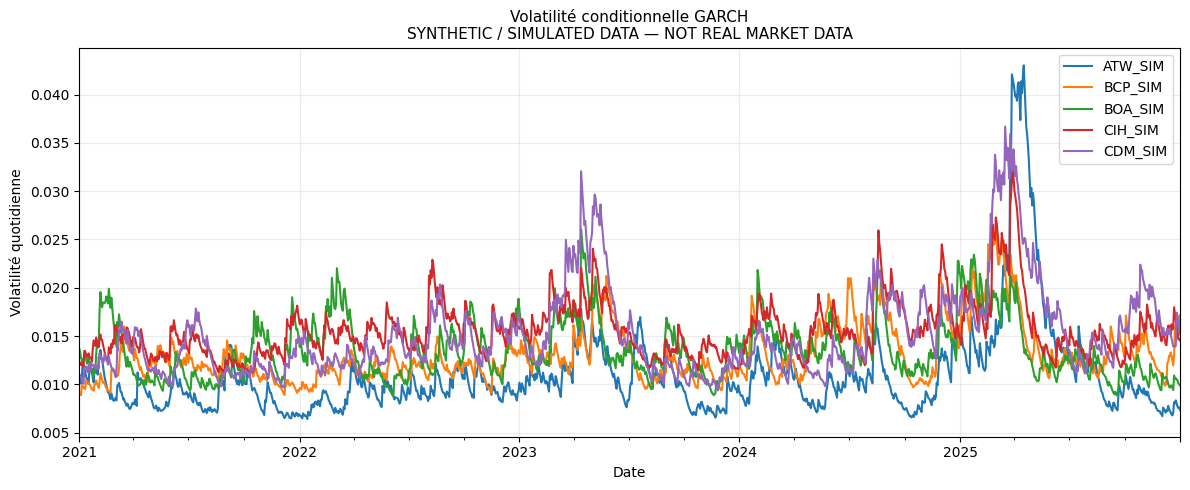

,ATW_SIM,BCP_SIM,BOA_SIM,CIH_SIM,CDM_SIM
count,1304.000000,1304.000000,1304.000000,1304.000000,1304.000000
mean,-0.039665,-0.007130,-0.018801,-0.048120,-0.043097
std,1.000011,0.999994,0.999597,0.998797,0.999085
min,-4.051080,-3.358496,-4.476958,-4.626861,-3.299707
25%,-0.676441,-0.695072,-0.647937,-0.726662,-0.687232
50%,-0.070351,0.022708,-0.031727,-0.007646,-0.018153
75%,0.635735,0.623963,0.680011,0.620913,0.622332
max,3.796723,3.610511,3.005106,3.412739,3.531477


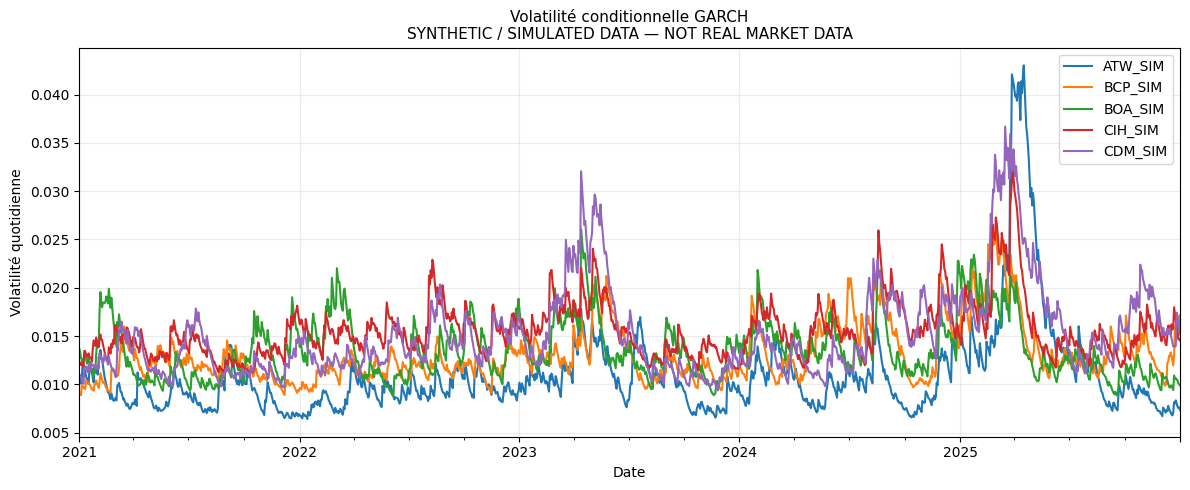

In [2]:
volatility = pd.DataFrame({name: fit.conditional_volatility for name, fit in models.items()})
standardized = pd.DataFrame({name: fit.standardized_residuals for name, fit in models.items()})
display(plot_series(volatility, 'Volatilité conditionnelle GARCH', 'Volatilité quotidienne'))
display(standardized.describe())
assert (volatility > 0).all().all()

Une somme $\alpha+\beta$ proche de 1 signifie une forte persistance de la volatilité. Ce diagnostic n'est pas une preuve de qualité prédictive; il faut également examiner les résidus, la convergence et les hypothèses de distribution.